# [8.5] Causal Scrubbing (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part5_causal_scrubbing/8.5_Causal_Scrubbing_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part5_causal_scrubbing/8.5_Causal_Scrubbing_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Here is the explanation of induction you wrote down in [1.2], for the two-layer attention-only model:

> On a repeated sequence, the induction heads (1.4 and 1.10) **query** with the current token. Their **keys** contain the previous token, moved there by the previous-token head
> 0.7. So at position $i$, an induction head attends to the position just after the last occurrence of the current token, reads that position's token through its **value**, and
> copies it to the output.

In [8.4], activation patching and ACDC agreed that the edges in this story are the most important edges in the model. That's evidence that the story names the right *components*.
But the story also makes claims about *information*: that the query carries the current token, that the key carries the previous token. Patching a component tells you it matters;
it doesn't tell you what it carries.

**Causal scrubbing** (Chan, Garriga-Alonso, Goldowsky-Dill, Greenblatt, Nitishinskaya, Radhakrishnan, Shlegeris & Thomas, Redwood Research, 2022) turns an explanation like this
into a single quantitative test. The idea fits in one sentence: *if the explanation is right, then replacing any activation with its value on a different input, one that the
explanation says is equivalent, shouldn't hurt the model.* So you resample everything the explanation says doesn't matter, keep (or resample consistently) everything it says does,
and measure how much of the model's performance survives.

Applied to the explanation above, it gives a surprisingly clear answer: the textbook story recovers only about **55%** of the model's induction performance. A refined story, in
which queries and keys carry two or three tokens of context instead of one, recovers about **90%**, close to the ceiling of everything the two induction heads do. By the end of
this section you'll have built causal scrubbing from scratch, found that refinement yourself, and learned the ways scrubbing can mislead you.

This section assumes [1.2] (induction heads, the two-layer model) and [8.4] (the edge-level view of a transformer, and circuit evaluation). We use the same model and the same
induction task as [8.4].

**Runtime and device.** The setup runs on CPU when neither MPS nor CUDA is available. Begin with the small resampling toy; the transformer sections load the two-layer
attention-only model. An accelerator is recommended for the per-position resampling sweeps, whose intermediate work grows with both batch size and sequence length. The saved plots
are reference outputs. Freeze any smaller batch or sequence before comparing hypotheses,
and record that changed configuration.

## Content & Learning Objectives

### 1️⃣ Resampling Ablations on a Toy

You'll implement causal scrubbing on a tiny hand-written computation where you know the answer: feature-preserving resampling, the loss-recovered metric, recursive hypotheses about
inner nodes, and why zero-ablation is not a neutral substitute.

> ##### Learning Objectives
>
> - Understand a hypothesis as a claim about which inputs are *equivalent* for each part of the computation
> - Implement feature-preserving resampling, and the loss-recovered metric
> - See that scrubbing tests the *expected loss*, which can make an activation that changes the output look unimportant
> - Understand why resampling ablations are more principled than zero or mean ablations

### 2️⃣ Scrubbing a Transformer: Which Components?

You'll implement the scrubbed forward pass for the two-layer model, test hypotheses about which heads and which edges matter, and find that the [1.2] circuit, scored by scrubbing,
recovers only about a third of the behaviour.

> ##### Learning Objectives
>
> - Implement scrubbing for a transformer: each input to a component is computed from its own (possibly resampled) input
> - Test component-level and edge-level hypotheses, against the "everything resampled" and "nothing resampled" anchors
> - Diagnose which part of a hypothesis is responsible for a low score

### 3️⃣ Scrubbing What the Heads Read

You'll test claims about *which token positions* each input of the induction heads carries information about, using per-position resampling, and refine the textbook explanation
until it recovers nearly all of the behaviour.

> ##### Learning Objectives
>
> - Implement per-position resampling, which tests "this activation only depends on these tokens"
> - Score the textbook induction hypothesis, and each of its claims separately
> - Refine a hypothesis using scrubbing as feedback, and use deliberately wrong hypotheses as controls
> - Connect the refined hypothesis to the components that implement it

### 4️⃣ How Scrubbing Can Mislead

You'll see how much the score depends on the resampling distribution, look at where a hypothesis fails rather than just how much, and write your own hypothesis.

> ##### Learning Objectives
>
> - Understand why the resampling distribution must be the task distribution, and what happens if it isn't
> - Look beyond an average score: per-position breakdowns
> - Know the limits of the method: what a high score does and doesn't establish

### ☆ Bonus

Full treeified scrubbing with an independent input per path, scrubbing on GPT-2's IOI circuit, the connection to interchange interventions, and further reading.

## Setup code

In [ ]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformer_lens==2.16.1 jaxtyping
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter8_automated_circuits"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [ ]:
import math
import statistics
import sys
from collections.abc import Callable
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch as t
from jaxtyping import Float, Int
from torch import Tensor
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter8_automated_circuits"
section = "part5_causal_scrubbing"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part5_causal_scrubbing.tests as tests
import part5_causal_scrubbing.utils as utils

MAIN = __name__ == "__main__"

# 1️⃣ Resampling Ablations on a Toy

> ##### Learning Objectives
>
> - Understand a hypothesis as a claim about which inputs are *equivalent* for each part of the computation
> - Implement feature-preserving resampling, and the loss-recovered metric
> - See that scrubbing tests the *expected loss*, which can make an activation that changes the output look unimportant
> - Understand why resampling ablations are more principled than zero or mean ablations

## A computation we understand completely

Before touching a transformer, let's scrub something where we can check every answer by hand. The "model" takes three digits $a, b, c \in \{0, \ldots, 9\}$ and computes two
intermediate nodes and an output:

$$
\begin{aligned}
s &= a + b \\
d &= c - 5 \\
\text{out} &= \cos(\pi s) + 0.1 \tanh(d)
\end{aligned}
$$

The task is to predict $y = (-1)^{a+b}$: $+1$ when $a + b$ is even, $-1$ when it's odd. Since $\cos(\pi s) = (-1)^s$, the model gets the sign right every time, with a small error
from the distractor term $0.1 \tanh(d)$. The loss is the mean squared error.

We know exactly how this model works. Let's see whether causal scrubbing agrees.

In [ ]:
def sample_toy(n: int, generator: t.Generator) -> Int[Tensor, "n 3"]:
    """n inputs (a, b, c), each digit uniform in 0..9."""
    return t.randint(0, 10, (n, 3), generator=generator)


def toy_nodes(x: Int[Tensor, "n 3"]) -> dict[str, Tensor]:
    a, b, c = x.float().unbind(-1)
    return {"a": a, "b": b, "c": c, "s": a + b, "d": c - 5}


def toy_output(s: Tensor, d: Tensor) -> Tensor:
    return t.cos(math.pi * s) + 0.1 * t.tanh(d)


def toy_label(x: Int[Tensor, "n 3"]) -> Tensor:
    return (-1.0) ** (x[:, 0] + x[:, 1]).float()


def mse(out: Tensor, y: Tensor) -> float:
    return ((out - y) ** 2).mean().item()


toy_generator = t.Generator().manual_seed(0)
TOY_POOL = sample_toy(20_000, toy_generator)  # the dataset we resample from
toy_x = sample_toy(4000, toy_generator)  # the inputs we evaluate on
nodes = toy_nodes(toy_x)
toy_original = mse(toy_output(nodes["s"], nodes["d"]), toy_label(toy_x))
print(f"Original loss: {toy_original:.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Original loss: 0.0081</pre>

</details>

## Hypotheses as equivalences

A causal-scrubbing hypothesis says, for each part of the computation, **which inputs are interchangeable**. "The output depends on $s$ only through its parity" means: for the
purpose of computing the output, any input $x'$ whose $a' + b'$ has the same parity as $a + b$ is as good as $x$. So we can test it by computing $s$ on such an $x'$ instead of $x$,
and checking that the loss doesn't go up.

Two anchors give the scale:

- the **original** loss (nothing resampled), and
- the **random** loss, where every node feeding the output is computed on a random, unrelated input from the dataset.

And the score of a hypothesis is the **loss recovered**:

$$
\text{loss recovered} = \frac{L_{\text{random}} - L_{\text{scrubbed}}}{L_{\text{random}} - L_{\text{original}}}
$$

which is 1 if scrubbing according to the hypothesis doesn't hurt at all, and 0 if it's as bad as resampling everything.

The core operation is **feature-preserving resampling**: for each input $x_i$, draw a random input from the dataset that has the same value of some feature.

### Exercise - implement `resample_matching` and `loss_recovered`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`resample_matching(x, feature, pool, generator)` takes inputs `x` (shape `(n, ...)`), a function `feature` mapping a batch of inputs to an integer tensor of shape `(batch,)`, and a
pool of candidate inputs. For each row $x_i$, it returns a row of `pool`, chosen uniformly at random among the rows $p$ with `feature(p) == feature(x_i)`. (Group the pool by
feature value; for each group of rows of `x`, sample indices into the matching group of the pool.)

`loss_recovered(scrubbed, original, random)` implements the formula above.

In [ ]:
def resample_matching(x: Tensor, feature: Callable[[Tensor], Tensor], pool: Tensor, generator: t.Generator) -> Tensor:
    """For each row of x, a uniformly random row of pool with the same feature value."""
    raise NotImplementedError()


def loss_recovered(scrubbed: float, original: float, random: float) -> float:
    raise NotImplementedError()


tests.test_resample_matching(resample_matching)
tests.test_loss_recovered(loss_recovered)

<details><summary>Solution</summary>

```python
def resample_matching(x: Tensor, feature: Callable[[Tensor], Tensor], pool: Tensor, generator: t.Generator) -> Tensor:
    """For each row of x, a uniformly random row of pool with the same feature value."""
    x_feat, pool_feat = feature(x), feature(pool)
    out = t.empty_like(x)
    for value in x_feat.unique():
        rows = (x_feat == value).nonzero().flatten()
        candidates = (pool_feat == value).nonzero().flatten()
        picks = candidates[t.randint(0, len(candidates), (len(rows),), generator=generator)]
        out[rows] = pool[picks]
    return out


def loss_recovered(scrubbed: float, original: float, random: float) -> float:
    return (random - scrubbed) / (random - original)
```
</details>

Some features we'll use, and the random anchor: every node feeding the output ($s$ and $d$) computed on its own random input. "No constraint" is just a constant feature.

In [ ]:
NO_CONSTRAINT = lambda rows: t.zeros(len(rows), dtype=t.long)
PARITY_OF_SUM = lambda rows: (rows[:, 0] + rows[:, 1]) % 2
SAME_A = lambda rows: rows[:, 0]
PARITY_OF_A = lambda rows: rows[:, 0] % 2
PARITY_OF_B = lambda rows: rows[:, 1] % 2
SAME_C = lambda rows: rows[:, 2]


def scrubbed_toy_loss(x: Tensor, s_from: Tensor, d_from: Tensor) -> float:
    """Loss when node s is computed on the inputs s_from and node d on d_from (the label always comes from x)."""
    return mse(toy_output(toy_nodes(s_from)["s"], toy_nodes(d_from)["d"]), toy_label(x))


toy_random = scrubbed_toy_loss(
    toy_x,
    resample_matching(toy_x, NO_CONSTRAINT, TOY_POOL, toy_generator),
    resample_matching(toy_x, NO_CONSTRAINT, TOY_POOL, toy_generator),
)
print(f"Random loss: {toy_random:.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Random loss: 2.0275</pre>

</details>

That's what you'd expect: with $s$ computed on a random input, the sign is wrong half the time, and a wrong sign costs $(\pm 2)^2 = 4$, so the loss is about 2.

### Exercise - score four hypotheses

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

For each hypothesis below, choose `s_from` and `d_from` (by calling `resample_matching` with the right feature, or using `toy_x` itself where the hypothesis says to keep the real
input), compute the scrubbed loss and the loss recovered, and fill in the dictionary `toy_scores` with `{name: (scrubbed loss, loss recovered)}`.

1. **"$d$ doesn't matter"**: $s$ is computed on the real input, $d$ on a random one.
2. **"The output depends on $s$ only through its parity"**: $s$ on an input with the same parity of $a + b$; $d$ random.
3. **"The output depends on $s$ only through $a$"**: $s$ on an input with the same $a$; $d$ random.
4. **"The output depends on $d$ only through $c$"**: $s$ real, $d$ on an input with the same $c$. (A sanity check: this is literally how $d$ is computed.)

Before running it, predict which will score close to 1.

In [ ]:
def resample(feature: Callable[[Tensor], Tensor]) -> Tensor:
    return resample_matching(toy_x, feature, TOY_POOL, toy_generator)


toy_scores = {}  # name -> (scrubbed loss, loss recovered)

for name, (scrubbed, recovered) in toy_scores.items():
    print(f"{name:<24} scrubbed loss {scrubbed:.4f}   loss recovered {recovered:+.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">d doesn't matter         scrubbed loss 0.0080   loss recovered +1.000
s only via its parity    scrubbed loss 0.0080   loss recovered +1.000
s only via a             scrubbed loss 1.9540   loss recovered +0.036
d only via c             scrubbed loss 0.0081   loss recovered +1.000</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Three of the four hypotheses score 1.000, and "$s$ only via $a$" scores 0.04.

- **"$d$ doesn't matter" passes, even though $d$ changes the output**: the output contains $0.1 \tanh(d)$. Scrubbing asks whether replacing $d$ with its value on another input changes the *loss*, on average. $d$'s contribution has nothing to do with the label, so a random $d$ is exactly as good as the real one. This is the most important thing to understand about causal scrubbing: it tests whether you've explained the model's *performance*, not whether you can reproduce every activation.
- **"$s$ only via its parity" passes**: the output uses $\cos(\pi s)$, which depends only on the parity of $s$.
- **"$s$ only via $a$" fails** (0.04): an input with the same $a$ but a random $b$ gets the parity of $a + b$ right only half the time, which is no better than random.
- **"$d$ only via $c$" passes** trivially, since $d$ is computed from $c$. That makes it a useful sanity check: if a hypothesis that's true by construction fails, the bug is in your scrubbing code.
</details>


<details><summary>Solution</summary>

```python
def resample(feature: Callable[[Tensor], Tensor]) -> Tensor:
    return resample_matching(toy_x, feature, TOY_POOL, toy_generator)


toy_hypotheses = {
    "d doesn't matter": (toy_x, resample(NO_CONSTRAINT)),
    "s only via its parity": (resample(PARITY_OF_SUM), resample(NO_CONSTRAINT)),
    "s only via a": (resample(SAME_A), resample(NO_CONSTRAINT)),
    "d only via c": (toy_x, resample(SAME_C)),
}
toy_scores = {}
for name, (s_from, d_from) in toy_hypotheses.items():
    scrubbed = scrubbed_toy_loss(toy_x, s_from, d_from)
    toy_scores[name] = (scrubbed, loss_recovered(scrubbed, toy_original, toy_random))

for name, (scrubbed, recovered) in toy_scores.items():
    print(f"{name:<24} scrubbed loss {scrubbed:.4f}   loss recovered {recovered:+.3f}")
```
</details>

## Hypotheses about inner nodes: treeification

So far each hypothesis said something about the inputs to the *output*. A hypothesis can also say something about how an inner node is computed: "the parity of $s$ is determined by
the parity of $a$ and the parity of $b$". To test that, we compute $a$ on one resampled input (with the same parity of $a$) and $b$ on *another* (with the same parity of $b$), and
add them to get $s$.

Notice what just happened. $a$ and $b$ are now computed from *different* inputs, so the "model" we're running isn't the original computation graph any more: it's a **tree**, in
which every path from an input to the output can have its own input. Causal scrubbing always works on this treeified version of the model. That's what lets it test claims about
each path separately, and it's the main thing that distinguishes it from ordinary activation patching.

### Exercise - a recursive hypothesis

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Compute the scrubbed loss for **"the output depends on $s$ only through its parity, and $s$'s parity depends only on the parities of $a$ and $b$"**: $a$ comes from an input with
the same parity of $a$, $b$ from an independent input with the same parity of $b$, and $d$ is random. Also score the wrong recursive hypothesis **"... and $s$'s parity depends only
on the parity of $a$"** ($b$ random). Add both to `toy_scores`.

In [ ]:
# YOUR CODE HERE - add two entries to toy_scores

for name in ["s = parity(a) + parity(b)", "s = parity(a) + anything"]:
    print(f"{name:<28} scrubbed loss {toy_scores[name][0]:.4f}   loss recovered {toy_scores[name][1]:+.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">s = parity(a) + parity(b)    scrubbed loss 0.0080   loss recovered +1.000
s = parity(a) + anything     scrubbed loss 1.9519   loss recovered +0.037</pre>

</details>


<details><summary>Solution</summary>

```python
d_random = toy_nodes(resample(NO_CONSTRAINT))["d"]
for name, b_feature in [("s = parity(a) + parity(b)", PARITY_OF_B), ("s = parity(a) + anything", NO_CONSTRAINT)]:
    a = toy_nodes(resample(PARITY_OF_A))["a"]
    b = toy_nodes(resample(b_feature))["b"]
    scrubbed = mse(toy_output(a + b, d_random), toy_label(toy_x))
    toy_scores[name] = (scrubbed, loss_recovered(scrubbed, toy_original, toy_random))

for name in ["s = parity(a) + parity(b)", "s = parity(a) + anything"]:
    print(f"{name:<28} scrubbed loss {toy_scores[name][0]:.4f}   loss recovered {toy_scores[name][1]:+.3f}")
```
</details>

## Why resample, rather than zero out?

Most ablation methods replace an activation with zero, or with its mean. Causal scrubbing insists on replacing it with its value on *another real input*. Here's why. Let's
zero-ablate $d$ (set $d = 0$), and mean-ablate it, and compare with resampling it.


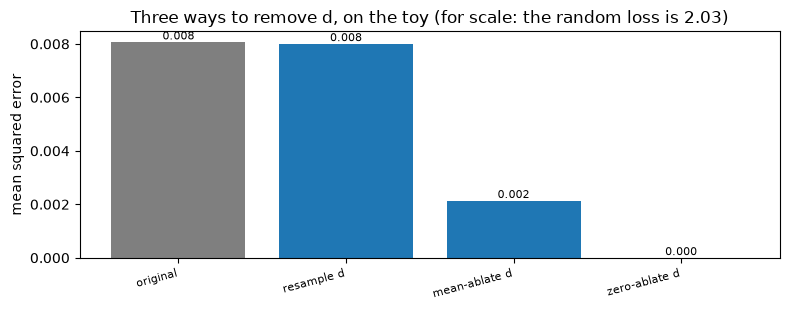

In [ ]:
s_real = nodes["s"]
zero_d = mse(toy_output(s_real, t.zeros_like(nodes["d"])), toy_label(toy_x))
mean_d = mse(toy_output(s_real, nodes["d"].mean().expand_as(nodes["d"])), toy_label(toy_x))
resampled_d = toy_scores["d doesn't matter"][0]
losses = {"original": toy_original, "resample d": resampled_d, "mean-ablate d": mean_d, "zero-ablate d": zero_d}
for name, value in losses.items():
    print(f"{name:<14} loss {value:.4f}   loss recovered {loss_recovered(value, toy_original, toy_random):+.3f}")
utils.plot_toy_losses(losses, f"Three ways to remove d, on the toy (for scale: the random loss is {toy_random:.2f})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">original       loss 0.0081   loss recovered +1.000
resample d     loss 0.0080   loss recovered +1.000
mean-ablate d  loss 0.0021   loss recovered +1.003
zero-ablate d  loss 0.0000   loss recovered +1.004</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Resampling $d$ leaves the loss where it was (0.0080 against 0.0081, the same up to sampling noise). Mean-ablating $d$ drops it to 0.0021, and zero-ablating to exactly 0: by those
measures, "removing" $d$ makes the model *better than itself*, with a loss recovered slightly above 1.

Setting $d$ to a constant puts the model in a state it never visits on real inputs. Here that state happens to be harmless (it removes a source of noise); in a real network, it's
often harmful, and then zero ablation makes a component look more important than it is. Either way, the ablation is answering a different question from the one we meant to ask,
which is: does the model's performance depend on *which* value of $d$ it gets? Resampling asks exactly that, because the replacement is always a value $d$ could really have had.
This is the argument for resampling ablations made in the causal scrubbing writeup, and it's why [8.1] preferred corrupted-prompt ablations to zero ablation.
</details>

## Summary of 1️⃣

- A causal-scrubbing hypothesis says which inputs are interchangeable for each part of a computation. It's tested by recomputing each part on a resampled input that the hypothesis says is equivalent, and measuring how much of the original performance survives (loss recovered, between 0 for "everything resampled" and 1 for the model).
- The core operation is feature-preserving resampling from the data distribution.
- Scrubbing tests the *expected loss*, not the output. An activation that changes the output can still pass as "unimportant" if swapping it for another input's value doesn't change the loss on average.
- Hypotheses about inner nodes are tested on a *treeified* model, in which different paths to the output can see different inputs.
- Zero and mean ablation put activations in states the model never sees on real data, and can make a model look better (or worse) than it is. Resampling keeps every activation on-distribution.

# 2️⃣ Scrubbing a Transformer: Which Components?

> ##### Learning Objectives
>
> - Implement scrubbing for a transformer: each input to a component is computed from its own (possibly resampled) input
> - Test component-level and edge-level hypotheses, against the "everything resampled" and "nothing resampled" anchors
> - Diagnose which part of a hypothesis is responsible for a low score

## The model and the task

We use the two-layer attention-only model and the induction task from [8.4]: prompts $[\text{BOS}, r_1, \ldots, r_n, r_1, \ldots, r_n]$ of random tokens, with $n = 20$, and the
loss is the cross-entropy of the next token at the positions where induction can work (positions $n + 1$ to $2n - 1$).

There's one important difference from [8.4]. There, cutting an edge meant replacing a sender's output with its value on a fixed *corrupted* prompt (unrepeated random tokens).
Causal scrubbing instead resamples from the **task distribution**: other prompts of exactly the same kind, here other repeated random sequences. We'll come back to why that matters
in 4️⃣.

In [ ]:
model = utils.load_attn_only_2l(device)
BOS, HALF_LEN = model.tokenizer.bos_token_id, 20
POS = slice(HALF_LEN + 1, 2 * HALF_LEN)
N_HEADS = model.cfg.n_heads

data_generator = t.Generator().manual_seed(0)
tokens = utils.repeated_random_tokens(BOS, (64,), HALF_LEN, data_generator, device)
SEQ = tokens.shape[1]


def induction_loss(logits: Float[Tensor, "batch seq d_vocab"], tokens: Int[Tensor, "batch seq"]) -> float:
    """Mean next-token cross-entropy at the induction positions."""
    logprobs = logits[:, POS].log_softmax(dim=-1)
    return -logprobs.gather(-1, tokens[:, POS.start + 1 : POS.stop + 1, None]).mean().item()


with t.no_grad():
    ORIGINAL = induction_loss(model(tokens), tokens)
print(f"{tokens.shape[0]} prompts of length {SEQ}; original induction loss {ORIGINAL:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">64 prompts of length 41; original induction loss 3.199</pre>

</details>

## The pieces of a scrubbed forward pass

In the toy, the nodes were $s$ and $d$. Here they are the senders of [8.4]: the token embedding, the 12 layer-0 heads and the 12 layer-1 heads. Since the model has only two layers,
the tree we need is shallow:

- the **logits** read the embedding, the layer-0 heads and the layer-1 heads;
- each **layer-1 head** reads, through its query, key and value, the embedding and the layer-0 heads;
- the **layer-0 heads** read the embedding, and we won't make claims about their inputs (so they're always computed on whatever input they're given).

A hypothesis will say, for the logits, which senders' outputs are computed on the real input (all others come from a resampled input); and, for the query, key and value input of
each kept layer-1 head, which senders it reads from the real input. We need three building blocks: the layer-0 outputs on any input, a layer-1 head's output given its three inputs,
and the input of a layer-1 head under a claim about its senders.

### Exercise - layer-0 outputs

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `layer0_outputs`, which returns a dict mapping `"embed"` and `"0.0"`, ..., `"0.11"` to that sender's output, each of shape `(*batch_dims, seq, d_model)`. The input can
have any number of leading batch dimensions (we'll need this in 3️⃣): flatten them, run the model with `stop_at_layer=1` caching `hook_embed` and `blocks.0.attn.hook_z`, compute
each head's output as `z[:, :, h] @ model.W_O[0, h]`, and reshape back.

Computing head outputs from `hook_z` yourself (rather than using TransformerLens's `hook_result`) keeps the memory small: `hook_result` materialises a tensor with an extra `d_head`
dimension, which is fine for 64 prompts and catastrophic for the 2,600 we'll run at once later.

In [ ]:
@t.no_grad()
def layer0_outputs(model: HookedTransformer, tokens: Int[Tensor, "... seq"]) -> dict[str, Float[Tensor, "... seq d_model"]]:
    raise NotImplementedError()


tests.test_layer0_outputs(layer0_outputs, model, tokens[:4])

<details><summary>Solution</summary>

```python
@t.no_grad()
def layer0_outputs(model: HookedTransformer, tokens: Int[Tensor, "... seq"]) -> dict[str, Float[Tensor, "... seq d_model"]]:
    batch_dims, seq = tokens.shape[:-1], tokens.shape[-1]
    flat = tokens.reshape(-1, seq)
    _, cache = model.run_with_cache(flat, names_filter=lambda name: name in ("hook_embed", "blocks.0.attn.hook_z"), stop_at_layer=1)
    z = cache["blocks.0.attn.hook_z"]
    outputs = {"embed": cache["hook_embed"]}
    for head in range(model.cfg.n_heads):
        outputs[f"0.{head}"] = z[:, :, head] @ model.W_O[0, head]
    return {name: out.reshape(*batch_dims, seq, -1) for name, out in outputs.items()}
```
</details>

### Exercise - a layer-1 head from three inputs

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `head1_forward`, which computes the output (after $W_O$) of layer-1 head `head` given *separate* residual-stream inputs for its query, key and value, each of shape
`(batch, seq, d_model)`. Remember the shortformer positional embedding: add `model.W_pos[:seq]` to the query and key inputs only. You wrote the multi-head version of this in
[8.4]'s `run_graph`.

In [ ]:
def head1_forward(
    model: HookedTransformer,
    head: int,
    q_in: Float[Tensor, "batch seq d_model"],
    k_in: Float[Tensor, "batch seq d_model"],
    v_in: Float[Tensor, "batch seq d_model"],
) -> Float[Tensor, "batch seq d_model"]:
    raise NotImplementedError()


tests.test_head1_forward(head1_forward, model, tokens[:8])

<details><summary>Solution</summary>

```python
def head1_forward(
    model: HookedTransformer,
    head: int,
    q_in: Float[Tensor, "batch seq d_model"],
    k_in: Float[Tensor, "batch seq d_model"],
    v_in: Float[Tensor, "batch seq d_model"],
) -> Float[Tensor, "batch seq d_model"]:
    seq = q_in.shape[1]
    pos = model.W_pos[:seq]
    q = (q_in + pos) @ model.W_Q[1, head] + model.b_Q[1, head]
    k = (k_in + pos) @ model.W_K[1, head] + model.b_K[1, head]
    v = v_in @ model.W_V[1, head] + model.b_V[1, head]
    scores = q @ k.transpose(-1, -2) / model.cfg.d_head**0.5
    causal = t.triu(t.ones(seq, seq, dtype=t.bool, device=q_in.device), diagonal=1)
    pattern = scores.masked_fill(causal, float("-inf")).softmax(dim=-1)
    return (pattern @ v) @ model.W_O[1, head]
```
</details>

### Exercise - inputs that read only some senders

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `sender_restricted_input`. It returns the residual stream that a layer-1 head reads, under the claim "this input reads only the senders in `senders` (from the real
input)":

$$
x_{\text{in}} = b_O^{(0)} + \sum_{s \in \text{senders}} \text{out}_s(x) + \sum_{s \notin \text{senders}} \text{out}_s(x')
$$

where $x'$ is a resample from the task distribution. Draw it with exactly one call, `utils.repeated_random_tokens(BOS, tokens.shape[:-1], HALF_LEN, generator, tokens.device)` (the
test reproduces it). If `senders` is `None`, every sender reads the real input, and you don't need a resample.

(We use one shared resample for all the senders that aren't claimed. Full causal scrubbing would give each of them its own independent input; see the bonus section.)

In [ ]:
@t.no_grad()
def sender_restricted_input(
    model: HookedTransformer, tokens: Int[Tensor, "... seq"], senders: list[str] | None, generator: t.Generator
) -> Float[Tensor, "... seq d_model"]:
    raise NotImplementedError()


tests.test_sender_restricted_input(sender_restricted_input, layer0_outputs, model, tokens[:4], HALF_LEN)

<details><summary>Solution</summary>

```python
@t.no_grad()
def sender_restricted_input(
    model: HookedTransformer, tokens: Int[Tensor, "... seq"], senders: list[str] | None, generator: t.Generator
) -> Float[Tensor, "... seq d_model"]:
    real = layer0_outputs(model, tokens)
    if senders is None:
        return model.b_O[0] + sum(real.values())
    resample = utils.repeated_random_tokens(BOS, tokens.shape[:-1], HALF_LEN, generator, tokens.device)
    other = layer0_outputs(model, resample)
    return model.b_O[0] + sum(real[name] if name in senders else other[name] for name in real)
```
</details>

## The scrubbed forward pass

Now we can assemble everything. We'll write a hypothesis as a dictionary:

- `hypothesis["logits"]`: the list of senders whose outputs the logits read from the real input. Every other sender's output is taken from the *unmodified model* run on a resample. (A sender the hypothesis says is unimportant is resampled *with everything upstream of it*: the hypothesis says nothing about its inside.)
- `hypothesis[(head, "q")]`, `(head, "k")`, `(head, "v")` for each kept layer-1 head: a `Claim` about that input. In this part a claim only lists senders; in 3️⃣ we'll add claims about positions.

Kept layer-1 heads are recomputed with `head1_forward` from their claimed inputs, so that a claim about a head's inputs affects what the logits see.

In [ ]:
@dataclass
class Claim:
    """What one input of a layer-1 head depends on."""

    senders: list[str] | None = None  # which senders it reads from the real input (None: all of them)
    offsets: list[int] | None = None  # which token positions, relative to the reader's position, the information comes from (None: any) - used from 3️⃣ on


@t.no_grad()
def layer1_outputs(model: HookedTransformer, tokens: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch seq head d_model"]:
    """The real outputs of all layer-1 heads (after W_O), on the given tokens."""
    _, cache = model.run_with_cache(tokens, names_filter="blocks.1.attn.hook_z")
    return t.einsum("bphe,hed->bphd", cache["blocks.1.attn.hook_z"], model.W_O[1])

### Exercise - implement `scrubbed_loss`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Implement `scrubbed_loss(model, tokens, hypothesis, generator)`, which returns the induction loss of the model scrubbed according to `hypothesis`. Build the final residual stream
(the logits' input) as:

$$
b_O^{(0)} + b_O^{(1)} + \sum_{\text{senders } s} \begin{cases} \text{out}_s(x) & s \in \texttt{hypothesis["logits"]} \\ \text{out}_s(x'_s) & \text{otherwise} \end{cases}
$$

where:

- for the embedding and layer-0 heads, $\text{out}_s(x)$ comes from `layer0_outputs(model, tokens)`;
- for a kept layer-1 head, $\text{out}_s(x)$ is `head1_forward` applied to its three claimed inputs, each computed with `claimed_input(model, tokens, claim, generator)` (provided below; in this part it just calls `sender_restricted_input`). Use `Claim()` for an input the hypothesis doesn't mention;
- for a resampled sender, $\text{out}_s(x'_s)$ is its real output on a resample. Use one resample for the embedding and all layer-0 heads together, and one for all layer-1 heads together (draw them with `utils.repeated_random_tokens`).

Then unembed (`@ model.W_U + model.b_U`) and return `induction_loss`. Missing keys mean "resample": `scrubbed_loss(model, tokens, {}, generator)` is the random anchor.

In [ ]:
def claimed_input(model: HookedTransformer, tokens: Tensor, claim: Claim, generator: t.Generator) -> Tensor:
    """The input of a layer-1 head under a claim. (In 3️⃣ you'll extend this to claims about positions.)"""
    assert claim.offsets is None, "Claims about positions come in section 3️⃣"
    return sender_restricted_input(model, tokens, claim.senders, generator)


@t.no_grad()
def scrubbed_loss(model: HookedTransformer, tokens: Int[Tensor, "batch seq"], hypothesis: dict, generator: t.Generator) -> float:
    raise NotImplementedError()


tests.test_scrubbed_loss(scrubbed_loss, model, tokens, ORIGINAL)

<details>
<summary>Hint</summary>

Compute `real0 = layer0_outputs(model, tokens)` and the two resampled sets of outputs first. Start the residual stream from both $b_O$ terms plus the sum over the 13 entries of
`real0`/`other0`, choosing for each name according to `kept`. Then loop over the 12 layer-1 heads.
</details>


<details><summary>Solution</summary>

```python
def claimed_input(model: HookedTransformer, tokens: Tensor, claim: Claim, generator: t.Generator) -> Tensor:
    """The input of a layer-1 head under a claim. (In 3️⃣ you'll extend this to claims about positions.)"""
    assert claim.offsets is None, "Claims about positions come in section 3️⃣"
    return sender_restricted_input(model, tokens, claim.senders, generator)


@t.no_grad()
def scrubbed_loss(model: HookedTransformer, tokens: Int[Tensor, "batch seq"], hypothesis: dict, generator: t.Generator) -> float:
    kept = hypothesis.get("logits", [])
    real0 = layer0_outputs(model, tokens)
    other0 = layer0_outputs(model, utils.repeated_random_tokens(BOS, tokens.shape[:-1], HALF_LEN, generator, tokens.device))
    other1 = layer1_outputs(model, utils.repeated_random_tokens(BOS, tokens.shape[:-1], HALF_LEN, generator, tokens.device))
    resid = model.b_O[0] + model.b_O[1] + sum(real0[name] if name in kept else other0[name] for name in real0)
    for head in range(model.cfg.n_heads):
        if f"1.{head}" in kept:
            inputs = [claimed_input(model, tokens, hypothesis.get((head, c), Claim()), generator) for c in "qkv"]
            resid = resid + head1_forward(model, head, *inputs)
        else:
            resid = resid + other1[:, :, head]
    return induction_loss(resid @ model.W_U + model.b_U, tokens)
```
</details>

Scrubbing is random, so we'll average each hypothesis over a few resamples, and report the spread. Let's set up the anchors.

In [ ]:
N_RESAMPLES = 5
scrub_generator = t.Generator().manual_seed(1)


def score(hypothesis: dict, n: int = N_RESAMPLES, data: Tensor | None = None) -> tuple[float, float]:
    """Mean and standard deviation of loss recovered over n resamples."""
    data = tokens if data is None else data
    values = [loss_recovered(scrubbed_loss(model, data, hypothesis, scrub_generator), ORIGINAL, RANDOM) for _ in range(n)]
    return statistics.mean(values), statistics.stdev(values)


RANDOM = statistics.mean(scrubbed_loss(model, tokens, {}, scrub_generator) for _ in range(N_RESAMPLES))
EVERYTHING = {"logits": ["embed"] + [f"{layer}.{h}" for layer in range(2) for h in range(N_HEADS)]}
print(f"original loss {ORIGINAL:.3f}, random loss {RANDOM:.3f}")
print(f"keep everything: loss recovered {score(EVERYTHING, n=2)[0]:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">original loss 3.199, random loss 14.114
keep everything: loss recovered 1.000</pre>

</details>

The model's loss at the induction positions is 3.20 nats. Resampling everything (every sender the logits read, taken from another repeated sequence) gives 14.11, which is worse
than a uniform guess over the vocabulary ($\ln 50278 \approx 10.8$): the resampled heads confidently predict the *other* sequence's tokens. Keeping everything reproduces the
original loss exactly, which is the sanity check that your scrubbed forward pass is wired correctly.

## Which heads, and which edges?

Our first hypotheses are about components:

1. **"Only the induction heads"**: the logits read the embedding (the direct path) and heads 1.4 and 1.10 from the real input; every other head's output is resampled. The induction heads' own inputs are left alone.
2. **"The [1.2] circuit"**: as above, and also each induction head's query reads only the embedding, its key reads only head 0.7, and its value reads only the embedding. This is the circuit from [1.2], and the reference circuit we used in [8.4].
3. **"The [1.2] circuit, plus the embedding into the keys"**, in case the keys need the current token too.

In [ ]:
INDUCTION = [4, 10]
INDUCTION_LOGITS = ["embed", "1.4", "1.10"]


def induction_hypothesis(q: Claim = Claim(), k: Claim = Claim(), v: Claim = Claim()) -> dict:
    """The logits read the direct path and the two induction heads; both heads' inputs follow the given claims."""
    hypothesis = {"logits": INDUCTION_LOGITS}
    for head in INDUCTION:
        hypothesis[(head, "q")], hypothesis[(head, "k")], hypothesis[(head, "v")] = q, k, v
    return hypothesis


component_results = {
    "only the induction heads (+ direct path)": score(induction_hypothesis()),
    "[1.2] circuit: q<-embed, k<-0.7, v<-embed": score(induction_hypothesis(q=Claim(["embed"]), k=Claim(["0.7"]), v=Claim(["embed"]))),
    "[1.2] circuit + embed into the keys": score(induction_hypothesis(q=Claim(["embed"]), k=Claim(["embed", "0.7"]), v=Claim(["embed"]))),
}
for name, (mean, std) in component_results.items():
    print(f"{name:<44} loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">only the induction heads (+ direct path)     loss recovered 0.938 ± 0.004
[1.2] circuit: q&lt;-embed, k&lt;-0.7, v&lt;-embed    loss recovered 0.327 ± 0.007
[1.2] circuit + embed into the keys          loss recovered 0.341 ± 0.008</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

Keeping only the two induction heads and the direct path, and resampling the outputs of the other 22 heads, recovers 0.94: the claim that heads 1.4 and 1.10 do the induction is
largely right. That's the ceiling for everything that follows, since the later hypotheses keep the same components and make further claims about their inputs.

But the [1.2] circuit recovers only 0.33. Saying where each induction head's inputs come from (query and value from the embedding, key from head 0.7) costs two thirds of the
behaviour, and letting the keys read the embedding as well barely helps (0.34). Something in the circuit's claims about the inputs is badly wrong.
</details>

### Exercise - which claim is wrong?

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

The [1.2] circuit makes three claims about the induction heads' inputs at once. Score each claim on its own (with the other two inputs left unrestricted, i.e. `Claim()`), and store
the results in `single_claim_results`. Which one is responsible for most of the drop?

In [ ]:
single_claim_results = {}  # name -> (mean, std)
for name, (mean, std) in single_claim_results.items():
    print(f"{name:<28} loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">q reads only the embedding   loss recovered 0.387 ± 0.007
k reads only head 0.7        loss recovered 0.472 ± 0.005
v reads only the embedding   loss recovered 0.809 ± 0.004</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

All three claims cost something:

- "q reads only the embedding" is the worst (0.39): the queries read a lot from layer-0 heads.
- "k reads only 0.7" gives 0.47: 0.7 isn't the only source of what the keys need.
- Even "v reads only the embedding" loses something (0.81, against the ceiling of 0.94).

These are claims about *which senders* the inputs read. But think about what the queries need according to the textbook story: the current token. The embedding carries it, but so
does any layer-0 head that attends to the current position (in [8.4] you saw heads 0.9 and 0.11 attend to themselves about half and two thirds of the time). "Only the embedding"
throws that information away even if the story about *what* the query carries is right. The better question is what information the inputs carry, whichever senders it arrives
through. That's what 3️⃣ is about.
</details>


<details><summary>Solution</summary>

```python
single_claim_results = {
    "q reads only the embedding": score(induction_hypothesis(q=Claim(["embed"]))),
    "k reads only head 0.7": score(induction_hypothesis(k=Claim(["0.7"]))),
    "v reads only the embedding": score(induction_hypothesis(v=Claim(["embed"]))),
}
for name, (mean, std) in single_claim_results.items():
    print(f"{name:<28} loss recovered {mean:.3f} ± {std:.3f}")
```
</details>

## Summary of 2️⃣

- Scrubbing a transformer means recomputing each kept component from inputs the hypothesis says are equivalent. Senders the hypothesis says are unimportant are taken, with everything upstream of them, from a resample.
- The claim that only heads 1.4 and 1.10 (plus the direct path) matter for induction recovers 0.94 of the loss.
- The [1.2] circuit, which also says where each induction head's inputs come from, recovers only 0.33. Each of its three input claims costs something, the query claim most.
- Claims about *which senders* an input reads can fail because the same information is spread over several senders. That motivates claims about information instead.

# 3️⃣ Scrubbing What the Heads Read

> ##### Learning Objectives
>
> - Implement per-position resampling, which tests "this activation only depends on these tokens"
> - Score the textbook induction hypothesis, and each of its claims separately
> - Refine a hypothesis using scrubbing as feedback, and use deliberately wrong hypotheses as controls
> - Connect the refined hypothesis to the components that implement it

## Claims about information, not components

The claims in 2️⃣ were about *which senders* an input reads. The textbook story is really about *what information* an input carries: "the query carries the current token", "the key
carries the previous token". Several senders could carry the current token (the embedding obviously does, but so does any layer-0 head that attends to the current position), and it
shouldn't matter which.

Causal scrubbing can test that kind of claim directly. "The query at position $i$ depends only on token $i$" means: replacing the whole query input at position $i$ with the query
input computed on a *different sequence that has the same token at position $i$* shouldn't change anything. So for each position $i$ we need a different resample $x^{(i)}$, which
agrees with $x$ at position $i$ and is random everywhere else, and we take the query input at position $i$ from the run on $x^{(i)}$.

In general, a claim "this input at position $j$ depends only on the tokens at positions $j - d$ for $d \in D$" (the `offsets` field of `Claim`) is tested by building, for every
position $j$, a resample that copies $x$ at positions $\{j - d : d \in D\}$, running layer 0 on all of these resamples at once, and reading each position's input from its own
resample.

For example, the textbook story makes three such claims: queries $D = \{0\}$ (the current token), keys $D = \{1\}$ (the previous token), values $D = \{0\}$ (the token at the
attended position).

### Exercise - per-position resampling

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `per_position_resample(tokens, offsets, bos, half_len, generator)`. For a batch of `tokens` of shape `(batch, seq)`, it returns a tensor of shape `(seq, batch, seq)`:
copy number $j$ is a fresh sample from the task distribution, except that at positions $j - d$ (for $d$ in `offsets`, when $j - d \geq 0$) it agrees with `tokens`. Draw all the
fresh samples with one call to `utils.repeated_random_tokens(bos, (seq, batch), half_len, generator, tokens.device)`.

(Copying tokens into a repeated sequence breaks its repetition at those positions, so the resamples are only approximately from the task distribution. With one or a few positions
copied out of 41, this is a small effect, but keep it in mind.)

In [ ]:
def per_position_resample(
    tokens: Int[Tensor, "batch seq"], offsets: list[int], bos: int, half_len: int, generator: t.Generator
) -> Int[Tensor, "copy batch seq"]:
    raise NotImplementedError()


tests.test_per_position_resample(per_position_resample, tokens[:8], BOS, HALF_LEN)

<details><summary>Solution</summary>

```python
def per_position_resample(
    tokens: Int[Tensor, "batch seq"], offsets: list[int], bos: int, half_len: int, generator: t.Generator
) -> Int[Tensor, "copy batch seq"]:
    batch, seq = tokens.shape
    resamples = utils.repeated_random_tokens(bos, (seq, batch), half_len, generator, tokens.device)
    for j in range(seq):
        for d in offsets:
            if j - d >= 0:
                resamples[j, :, j - d] = tokens[:, j - d]
    return resamples
```
</details>

### Exercise - claims about positions

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Now redefine `claimed_input` to handle `claim.offsets`. If `offsets` is `None`, behave as before. Otherwise build the per-position resamples, compute `sender_restricted_input` on
all of them at once (it accepts extra leading dimensions, giving shape `(seq, batch, seq, d_model)`), and for each position $j$ take position $j$ of copy $j$, giving shape `(batch,
seq, d_model)`.

(`scrubbed_loss` looks up `claimed_input` by name each time it's called, so once you've redefined it, `scrubbed_loss` uses the new version automatically.)

In [ ]:
def claimed_input(model: HookedTransformer, tokens: Tensor, claim: Claim, generator: t.Generator) -> Tensor:
    """The input of a layer-1 head under a claim about which senders it reads and which positions they carry."""
    raise NotImplementedError()

<details>
<summary>Hint - the indexing</summary>

`inputs[positions, :, positions]` uses advanced indexing on the first and third dimensions together, which picks copy $j$ at position $j$ for every $j$ and gives a tensor of shape
`(seq, batch, d_model)`. Transpose the first two dimensions to get `(batch, seq, d_model)`.
</details>


<details><summary>Solution</summary>

```python
def claimed_input(model: HookedTransformer, tokens: Tensor, claim: Claim, generator: t.Generator) -> Tensor:
    """The input of a layer-1 head under a claim about which senders it reads and which positions they carry."""
    if claim.offsets is None:
        return sender_restricted_input(model, tokens, claim.senders, generator)
    copies = per_position_resample(tokens, claim.offsets, BOS, HALF_LEN, generator)
    inputs = sender_restricted_input(model, copies, claim.senders, generator)  # (copy, batch, seq, d_model)
    positions = t.arange(tokens.shape[1], device=tokens.device)
    return inputs[positions, :, positions].transpose(0, 1)
```
</details>

## The textbook hypothesis

Let's score the textbook story as a claim about information: queries carry the current token ($D = \{0\}$), keys the previous token ($D = \{1\}$), values the current token ($D =
\{0\}$). All senders are allowed (`senders=None`): we only constrain *which tokens* the inputs depend on. Then score each of the three claims on its own.

In [ ]:
textbook = induction_hypothesis(q=Claim(offsets=[0]), k=Claim(offsets=[1]), v=Claim(offsets=[0]))
info_results = {
    "textbook: q=[0], k=[1], v=[0]": score(textbook),
    "only: v depends on token j": score(induction_hypothesis(v=Claim(offsets=[0]))),
    "only: k depends on token j-1": score(induction_hypothesis(k=Claim(offsets=[1]))),
    "only: q depends on token i": score(induction_hypothesis(q=Claim(offsets=[0]))),
}
for name, (mean, std) in info_results.items():
    print(f"{name:<32} loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">textbook: q=[0], k=[1], v=[0]    loss recovered 0.546 ± 0.006
only: v depends on token j       loss recovered 0.934 ± 0.003
only: k depends on token j-1     loss recovered 0.534 ± 0.011
only: q depends on token i       loss recovered 0.573 ± 0.004</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The textbook story recovers 0.55: better than the component version of the same story (0.33), but still far from the ceiling of 0.94. Scoring the three claims one at a time
separates them cleanly:

- **The value claim is right.** "The value input at position $j$ depends only on token $j$" recovers 0.93, the same as the ceiling. An induction head copies the token at the position it attends to, and nothing else.
- **The key claim is wrong**: "the key at position $j$ depends only on token $j - 1$" recovers 0.53.
- **So is the query claim**: "the query at position $i$ depends only on token $i$" recovers 0.57.

So the keys and queries each carry *more* than one token. Nothing in [8.4]'s patching experiments could have told you that: patching measured which edges matter, and the edges in
the story were the right ones.
</details>

### Exercise - refine the hypothesis

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

The value claim holds, and the query and key claims don't. Use scrubbing as feedback to find out what the queries and keys *do* depend on. Score at least these:

- keys depending on tokens $\{0, 1\}$, $\{1, 2\}$ and $\{1, 2, 3\}$ back (queries and values unconstrained);
- queries depending on tokens $\{0, 1\}$ and $\{0, 1, 2\}$ back (keys and values unconstrained);
- your best combination of all three claims, with values at $\{0\}$.

Store everything in `refined_results`, and include two **controls**: hypotheses we know are wrong, which should score badly. Use "keys depend only on the token 5 positions back"
and "values depend only on the previous token".

In [ ]:
refined_results = {}  # name -> (mean, std)
for name, (mean, std) in refined_results.items():
    print(f"{name:<38} loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">k=[0,1]                                loss recovered 0.560 ± 0.003
k=[1,2]                                loss recovered 0.800 ± 0.006
k=[1,2,3]                              loss recovered 0.872 ± 0.006
q=[0,1]                                loss recovered 0.841 ± 0.004
q=[0,1,2]                              loss recovered 0.907 ± 0.006
refined: q=[0,1,2], k=[1,2,3], v=[0]   loss recovered 0.874 ± 0.007
refined+: q=[0..3], k=[0..4], v=[0]    loss recovered 0.925 ± 0.003
control: k=[5]                         loss recovered 0.121 ± 0.006
control: v=[1]                         loss recovered 0.052 ± 0.003</pre>

</details>


<details><summary>Solution</summary>

```python
refined_results = {
    "k=[0,1]": score(induction_hypothesis(k=Claim(offsets=[0, 1]))),
    "k=[1,2]": score(induction_hypothesis(k=Claim(offsets=[1, 2]))),
    "k=[1,2,3]": score(induction_hypothesis(k=Claim(offsets=[1, 2, 3]))),
    "q=[0,1]": score(induction_hypothesis(q=Claim(offsets=[0, 1]))),
    "q=[0,1,2]": score(induction_hypothesis(q=Claim(offsets=[0, 1, 2]))),
    "refined: q=[0,1,2], k=[1,2,3], v=[0]": score(induction_hypothesis(q=Claim(offsets=[0, 1, 2]), k=Claim(offsets=[1, 2, 3]), v=Claim(offsets=[0]))),
    "refined+: q=[0..3], k=[0..4], v=[0]": score(induction_hypothesis(q=Claim(offsets=[0, 1, 2, 3]), k=Claim(offsets=[0, 1, 2, 3, 4]), v=Claim(offsets=[0]))),
    "control: k=[5]": score(induction_hypothesis(k=Claim(offsets=[5]))),
    "control: v=[1]": score(induction_hypothesis(v=Claim(offsets=[1]))),
}
for name, (mean, std) in refined_results.items():
    print(f"{name:<38} loss recovered {mean:.3f} ± {std:.3f}")
```
</details>

## The hypothesis ladder

Let's put the main results on one chart: the anchors, the component hypotheses from 2️⃣, the textbook hypothesis, the refinements and the controls.


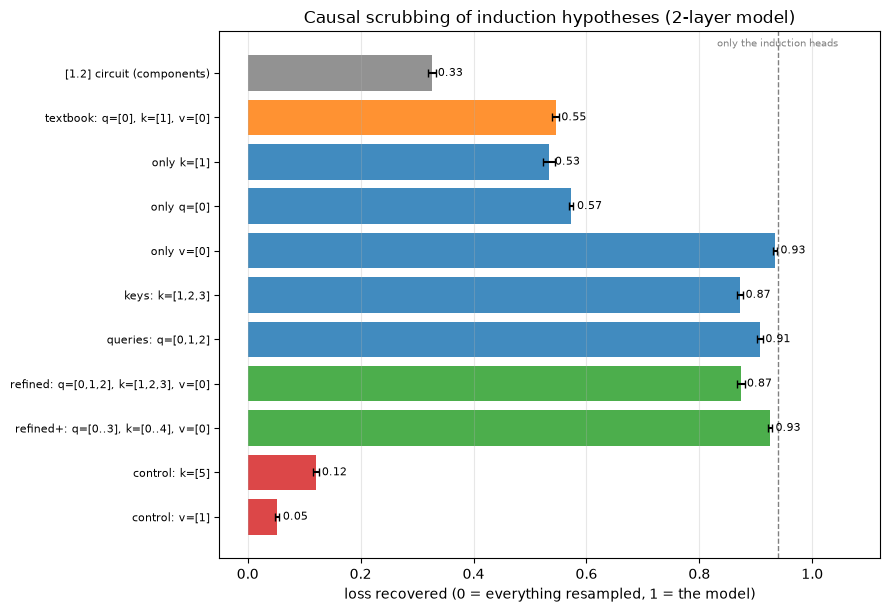

In [ ]:
ceiling = component_results["only the induction heads (+ direct path)"][0]
ladder = {
    "[1.2] circuit (components)": component_results["[1.2] circuit: q<-embed, k<-0.7, v<-embed"],
    "textbook: q=[0], k=[1], v=[0]": info_results["textbook: q=[0], k=[1], v=[0]"],
    "  only k=[1]": info_results["only: k depends on token j-1"],
    "  only q=[0]": info_results["only: q depends on token i"],
    "  only v=[0]": info_results["only: v depends on token j"],
    "keys: k=[1,2,3]": refined_results["k=[1,2,3]"],
    "queries: q=[0,1,2]": refined_results["q=[0,1,2]"],
    "refined: q=[0,1,2], k=[1,2,3], v=[0]": refined_results["refined: q=[0,1,2], k=[1,2,3], v=[0]"],
    "refined+: q=[0..3], k=[0..4], v=[0]": refined_results["refined+: q=[0..3], k=[0..4], v=[0]"],
    "control: k=[5]": refined_results["control: k=[5]"],
    "control: v=[1]": refined_results["control: v=[1]"],
}
colours = {name: "tab:red" for name in ladder if name.startswith("control")}
colours |= {name: "tab:green" for name in ladder if name.startswith("refined")}
colours |= {"textbook: q=[0], k=[1], v=[0]": "tab:orange", "[1.2] circuit (components)": "tab:gray"}
utils.plot_hypothesis_ladder(
    ladder, "Causal scrubbing of induction hypotheses (2-layer model)",
    reference={"only the induction heads": ceiling}, colours=colours,
)

<details>
<summary>Help - how should I interpret this?</summary>

Reading from the top:

- The [1.2] circuit as a claim about components (0.33), and the textbook story as a claim about information (0.55), both fall far short of the ceiling (the dashed line, 0.94: everything except the two induction heads and the direct path resampled).
- Of the textbook's three claims, only the value claim survives on its own (0.93).
- Keys that carry the tokens 1, 2 and 3 positions back recover 0.87; queries that carry the current token and the 2 before it recover 0.91. All three refined claims together give 0.87, and letting queries and keys see one more token ("refined+") gives 0.93, essentially the ceiling.
- Both controls fail, as they should: "keys depend only on the token 5 back" (0.12) and "values depend only on the previous token" (0.05) do far worse than even the textbook story. A method that gave these high scores wouldn't be telling us anything.

So in this model, the induction heads don't match single tokens. **The query carries the current token and the one or two before it, the key carries the previous two or three
tokens, and the head attends where these short *prefixes* match.** That's a fuzzier and more robust version of induction than the one in [1.2]: it can pick out the right occurrence
of a token that appears more than once, by checking that the tokens before it match too.

Notice how we found this: by proposing hypotheses, scoring them, and using the scores as feedback. Each refinement allows more positions, so it makes a weaker claim and you'd
expect it to score higher; it would be easy to "refine" all the way to claiming nothing (which scores exactly 1). What keeps this honest is that the final claims are still specific
(three or four positions, not "anything"), and that the controls show the method punishes wrong claims.
</details>

## Who carries the extra context?

The refined hypothesis says the queries and keys carry a few tokens of context. In [8.4] you met two layer-0 heads that could provide it: 0.7, which attends to the previous token,
and 0.4, which attends one to three tokens back (mostly two). Let's combine claims about senders and positions to ask where the context comes from.

In [ ]:
ALL_BUT_04 = ["embed"] + [f"0.{h}" for h in range(N_HEADS) if h != 4]
sender_results = {
    "q, k read only embed, 0.4 and 0.7": score(induction_hypothesis(q=Claim(["embed", "0.4", "0.7"]), k=Claim(["embed", "0.4", "0.7"]))),
    "q, k read every sender except 0.4": score(induction_hypothesis(q=Claim(ALL_BUT_04), k=Claim(ALL_BUT_04))),
    "q, k read every sender except 0.7": score(induction_hypothesis(q=Claim(["embed"] + [f"0.{h}" for h in range(N_HEADS) if h != 7]), k=Claim(["embed"] + [f"0.{h}" for h in range(N_HEADS) if h != 7]))),
}
for name, (mean, std) in sender_results.items():
    print(f"{name:<36} loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">q, k read only embed, 0.4 and 0.7    loss recovered 0.701 ± 0.006
q, k read every sender except 0.4    loss recovered 0.636 ± 0.003
q, k read every sender except 0.7    loss recovered 0.141 ± 0.004</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

- If the queries and keys read *only* the embedding, 0.4 and 0.7 (everything else resampled), the score is 0.70: these three senders carry most of what the queries and keys need, but not all.
- Removing just head 0.4 from the queries and keys drops the score from the ceiling of 0.94 to 0.64. Head 0.4, which attends one to three tokens back, supplies much of the extra context.
- Removing just head 0.7 is catastrophic (0.14): the previous-token head is still the backbone of the mechanism.

This fits what we saw in [8.4]. Head 0.7 provides the previous token, head 0.4 adds a blurrier view of the tokens before it, and together (with smaller contributions from other
layer-0 heads) they let the induction heads match multi-token prefixes. It's also why ACDC kept 0.4's edges into both the queries and the keys.
</details>

## Summary of 3️⃣

- A claim that an input "depends only on the tokens at these positions" is tested by per-position resampling: each position's input is computed on its own resampled sequence, which agrees with the real one only at those positions.
- The textbook induction story recovers 0.55 of the loss. Its value claim is right (0.93), but its query and key claims are each wrong.
- Refined claims (queries carry the current token and the 2 before it, keys carry the previous 3 tokens) recover 0.87-0.93, close to the 0.94 ceiling, while deliberately wrong claims score 0.05-0.12.
- The extra context arrives mostly through heads 0.7 and 0.4: resampling 0.4 out of the queries and keys costs 0.30, resampling 0.7 out costs 0.80.

# 4️⃣ How Scrubbing Can Mislead

> ##### Learning Objectives
>
> - Understand why the resampling distribution must be the task distribution, and what happens if it isn't
> - Look beyond an average score: per-position breakdowns
> - Know the limits of the method: what a high score does and doesn't establish

## Resampling from the wrong distribution

Causal scrubbing resamples from the task distribution: repeated random sequences. What if we had used unrepeated random sequences instead, like the corrupted prompts of [8.4]? It
sounds like a detail, but it changes what "an unimportant component" contributes. On an unrepeated sequence, a resampled induction head has nothing to copy and contributes little;
on a repeated one, it confidently predicts *some other* sequence's tokens.

Let's rescore a few hypotheses with the resampler swapped out. `utils.repeated_random_tokens` is used inside your functions, so we temporarily replace it with a sampler of
unrepeated sequences.

In [ ]:
def unrepeated_random_tokens(bos, batch_shape, half_len, generator, device):
    """Random sequences of the same length with no repetition: not the task distribution."""
    toks = t.randint(1000, 10000, (*batch_shape, 2 * half_len + 1), generator=generator)
    toks[..., 0] = bos
    return toks.to(device)


to_compare = {
    "only the induction heads": induction_hypothesis(),
    "[1.2] circuit (components)": induction_hypothesis(q=Claim(["embed"]), k=Claim(["0.7"]), v=Claim(["embed"])),
    "textbook": textbook,
    "refined": induction_hypothesis(q=Claim(offsets=[0, 1, 2]), k=Claim(offsets=[1, 2, 3]), v=Claim(offsets=[0])),
}
task_distribution = {name: score(h)[0] for name, h in to_compare.items()}
original_sampler = utils.repeated_random_tokens
utils.repeated_random_tokens = unrepeated_random_tokens
try:
    RANDOM_TASK = RANDOM
    RANDOM = statistics.mean(scrubbed_loss(model, tokens, {}, scrub_generator) for _ in range(N_RESAMPLES))
    wrong_distribution = {name: score(h)[0] for name, h in to_compare.items()}
    print(f"random loss: task distribution {RANDOM_TASK:.3f}, unrepeated sequences {RANDOM:.3f}\n")
finally:
    utils.repeated_random_tokens = original_sampler
    RANDOM = RANDOM_TASK

print(f"{'hypothesis':<28} {'task distribution':>18} {'unrepeated':>11}")
for name in to_compare:
    print(f"{name:<28} {task_distribution[name]:>18.3f} {wrong_distribution[name]:>11.3f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">random loss: task distribution 14.114, unrepeated sequences 12.887

hypothesis                    task distribution  unrepeated
only the induction heads                  0.939       0.942
[1.2] circuit (components)                0.316       0.246
textbook                                  0.548       0.509
refined                                   0.881       0.878</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The random anchor changes most: resampling everything from unrepeated sequences gives a loss of 12.9, against 14.1 from the task distribution. On an unrepeated sequence the
resampled heads have nothing to copy, so they push less confidently towards wrong tokens.

The scores move too, and not uniformly. (The task-distribution column is a fresh set of resamples, so it differs slightly from the numbers above.) The [1.2] circuit drops from 0.32
to 0.25 and the textbook story from 0.55 to 0.51, while "only the induction heads" and the refined hypothesis barely move. Hypotheses that resample a lot of the model are the most
sensitive to *what* they resample from. Here the conclusions survive the change, but the numbers you'd report don't, and in a model with more going on, the wrong distribution could
change a conclusion. Causal scrubbing's rule is to resample from the distribution the behaviour is defined on (here, repeated sequences), because only then does "replace this
activation with another input's" mean "give it a value it could really have had".
</details>

## Looking past the average

Loss recovered is a single number, averaged over every prompt and position. A hypothesis that scores 0.55 might be equally mediocre everywhere, or perfect on some positions and
useless on others, and those mean very different things. Let's break the scrubbed loss down by position in the second half.

### Exercise - per-position losses

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

`scrubbed_loss` averages over positions. Rather than changing it, temporarily replace the module-level `induction_loss` with a version that returns the loss at each induction
position (a tensor of shape `(n_positions,)`, averaged over prompts), call `scrubbed_loss` for the full model, the textbook and the refined hypothesis (averaging over 5 resamples),
and plot them with `utils.plot_per_position`. Restore `induction_loss` afterwards.


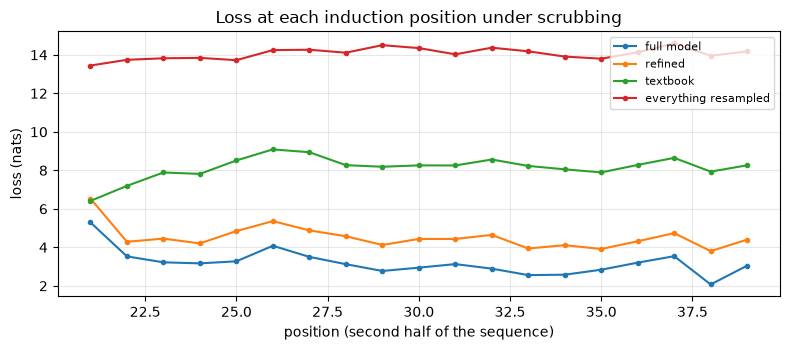

In [ ]:
# YOUR CODE HERE - compute per-position losses and plot them

<details><summary>Solution</summary>

```python
def per_position_induction_loss(logits: Tensor, tokens: Tensor) -> Tensor:
    logprobs = logits[:, POS].log_softmax(dim=-1)
    return -logprobs.gather(-1, tokens[:, POS.start + 1 : POS.stop + 1, None])[..., 0].mean(0)


mean_loss = induction_loss
induction_loss = per_position_induction_loss
try:
    curves = {
        name: sum(scrubbed_loss(model, tokens, h, scrub_generator) for _ in range(N_RESAMPLES)) / N_RESAMPLES
        for name, h in [("full model", EVERYTHING), ("refined", to_compare["refined"]), ("textbook", textbook), ("everything resampled", {})]
    }
finally:
    induction_loss = mean_loss

positions = list(range(POS.start, POS.stop))
utils.plot_per_position(curves, positions, "Loss at each induction position under scrubbing")
for name, curve in curves.items():
    print(f"{name:<22} first 3 positions {curve[:3].mean():.2f}   last 3 positions {curve[-3:].mean():.2f}")
```
</details>

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">full model             first 3 positions 4.02   last 3 positions 2.89
refined                first 3 positions 5.09   last 3 positions 4.31
textbook               first 3 positions 7.16   last 3 positions 8.28
everything resampled   first 3 positions 13.67   last 3 positions 14.24</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The full model's loss falls along the second half, from 4.0 nats in the first three induction positions to 2.9 in the last three: later positions have more context. The refined
hypothesis is uniformly a little worse than the model and follows the same trend (5.1 to 4.3). The textbook hypothesis does the opposite, getting *worse* along the sequence (7.2 to
8.3). That's what you'd expect if the model relies on multi-token context more as it goes: the textbook claims destroy precisely that context. The single average (0.55) hides this
shape completely.

At the very first induction position (position 21), the model, the refined and the textbook hypotheses are all worse than later on, and the two hypotheses are about equal. Here the
query is $r_1$, the first token of the repeat, and the tokens before it are the *end* of the first half, while the tokens before its earlier occurrence are BOS and nothing. There's
no matching prefix, so the extra context has nothing to offer.
</details>

## What a high score does and doesn't mean

By now you've seen scrubbing reject a story that every patching experiment in [8.4] seemed to support. It's worth being equally clear about what a *high* score establishes.

A high loss recovered means that the behaviour you measured survives every intervention the hypothesis licenses, on average over the task distribution. That's strong evidence that
the hypothesis captures what the model *uses*, at the level of detail the hypothesis states. It does not mean:

- **That it's the only such hypothesis.** A vaguer hypothesis makes fewer claims and resamples less, so it usually scores at least as well: the hypothesis that claims nothing scores exactly 1. Compare hypotheses at matched specificity, and prefer the most specific one that still scores well.
- **That it's complete.** Our refined hypothesis is close to the "only the induction heads" ceiling, but that ceiling is itself about 0.94, not 1: a few percent of the model's induction performance comes from elsewhere.
- **That every example is explained.** The score is an average of losses. Resampling can make some predictions better and others worse, and these can cancel. Per-position (or per-prompt) breakdowns catch some of this; the causal scrubbing authors recommend also checking the *distribution* of losses, not just its mean.
- **That the mechanism is the one you had in mind.** Scrubbing tests equivalence claims ("any input with the same tokens at these positions will do"), not how the model uses them. Two different mechanisms that depend on the same tokens pass the same test. You still need to look at attention patterns, weights or more specific hypotheses to say *how* the context is used.
- **That the numbers transfer.** They depend on the resampling distribution, on the metric (here, the loss on the correct token at induction positions) and on approximations like ours (per-position resamples that slightly break the repetition, shared resamples for unclaimed senders).

The causal scrubbing authors report that the explanations they tested, including some published ones, often recovered much less of the loss than expected, usually because of claims
that sounded too innocuous to check. "The query is the current token" is exactly that kind of claim.

## Try it yourself - write a hypothesis

Write your own hypothesis and score it. Some ideas:

- Does head 1.10's query need as much context as 1.4's? Give the two heads different claims (`hypothesis[(4, "q")]` and `hypothesis[(10, "q")]`).
- The keys of a token near the start of the sequence can't depend on tokens before position 0. Does the refined hypothesis still help in the first few positions of the second half?
- Combine claims about senders and positions: "the keys carry tokens 1-3 back, and they get them only from heads 0.4 and 0.7".

In [ ]:
my_hypothesis = induction_hypothesis(q=Claim(offsets=[0, 1]), k=Claim(senders=["embed", "0.4", "0.7"], offsets=[1, 2, 3]), v=Claim(offsets=[0]))
mean, std = score(my_hypothesis)
print(f"my hypothesis: loss recovered {mean:.3f} ± {std:.3f}")

<details>
<summary>Expected output (for the example hypothesis)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">my hypothesis: loss recovered 0.768 ± 0.006</pre>

</details>

## Summary of 4️⃣

- The resampling distribution is part of the test. Resampling from unrepeated sequences instead of the task distribution changes the random anchor and moves scores by up to 0.07 here, most for hypotheses that resample a lot.
- Averages hide structure: per position, the textbook hypothesis gets worse along the sequence while the model gets better.
- A high score shows that a hypothesis captures what the model uses, at the level of detail it states. It doesn't show that the hypothesis is unique or complete, that every example is explained, or which mechanism implements it.

# ☆ Bonus

## Full treeification

We took two shortcuts. All the senders that a claim leaves out share *one* resample, and the layer-0 heads are always computed on whatever input their reader was given, with no
claims of their own. Full causal scrubbing gives every path through the model its own input: each unclaimed sender gets an independent resample, and claims can be made about
layer-0 heads' inputs too ("0.7's output at position $j$ depends only on token $j - 1$"). Generalise `sender_restricted_input` to draw an independent resample per sender, and add
claims about layer-0 inputs. Does anything change for the hypotheses in this section? How much more compute does it need?

## Scrubbing the IOI circuit

The causal scrubbing writeup tests the IOI circuit of Wang et al. in GPT-2 Small, and finds that the paper's circuit recovers much less of the loss than its other evaluations
suggested. Using the GPT-2 edge graph from [8.2] and [8.4], implement scrubbing at the level of heads for IOI (the task distribution is IOI prompts with random names), and score
the circuit. Which claims fail?

## Scrubbing versus interchange interventions

Causal scrubbing is a close relative of the **interchange interventions** used in causal abstraction (Geiger et al.), which you'll meet in [11.3]: both replace activations with
their values on other inputs that a hypothesis says are equivalent. The main differences are that scrubbing resamples many inputs at once and scores a whole hypothesis with one
number, while interchange interventions usually test one alignment between a model variable and a high-level variable at a time. Read section 4 of Geiger et al. (2023) and write
down the scrubbing version of one of their experiments.

## Further reading

- Chan, Garriga-Alonso, Goldowsky-Dill, Greenblatt, Nitishinskaya, Radhakrishnan, Shlegeris & Thomas (2022), [*Causal Scrubbing: a method for rigorously testing interpretability hypotheses*](https://www.alignmentforum.org/posts/JvZhhzycHu2Yd57RN/causal-scrubbing-a-method-for-rigorously-testing). The original writeup, with the formal algorithm, and the [results on induction and paren-balancing](https://www.alignmentforum.org/posts/j6s9H9SHrEhEfuJnq/causal-scrubbing-results-on-induction-heads).
- Wang, Variengien, Conmy, Shlegeris & Steinhardt (2022), [*Interpretability in the Wild*](https://arxiv.org/abs/2211.00593). The IOI circuit, which causal scrubbing was applied to.
- Geiger, Wu, Lu, Rozner, Kreiss, Icard, Goodman & Potts (2023), [*Causal Abstraction for Faithful Model Interpretation*](https://arxiv.org/abs/2301.04709). The causal-abstraction view of the same idea.
- Miller, Chughtai & Saunders (2024), [*Transformer Circuit Faithfulness Metrics Are Not Robust*](https://arxiv.org/abs/2407.08734). On how much evaluation choices (like the resampling distribution in 4️⃣) move the numbers.